In [ ]:
# ==============================================================================
# INSTALASI DEPENDENSI (Jalankan sel ini HANYA jika pustaka belum terpasang)
# Hilangkan tanda pagar (#) pada baris di bawah untuk memasang dependensi:
# ==============================================================================
# !pip install numpy pandas requests matplotlib rasterio
# Atau instal seluruh dependensi modul melalui file requirements.txt:
# !pip install -r ../../requirements.txt


# Akuisisi Data dengan Python

Notebook ini mengambil data yang sama dengan panduan portal pada Modul Persiapan, tetapi lewat kode, sehingga langkahnya dapat diulang untuk kebun lain hanya dengan mengganti batas wilayah. Hanya jendela wilayah kerja yang dibaca, sehingga kita tidak perlu mengunduh satu adegan utuh yang ukurannya bisa mencapai 1–2 GB.

| Data | Sumber | Perlu akun? |
|---|---|---|
| Batas desa | Layanan peta Badan Informasi Geospasial (BIG) | Tidak |
| DEMNAS | Ina-Geoportal, diunduh manual per lembar | Ya |
| Sentinel-2 L2A | Katalog STAC Earth Search | Tidak |
| Sentinel-1 RTC | Katalog STAC Microsoft Planetary Computer | Tidak |
| Produk utuh Sentinel | Copernicus Data Space Ecosystem | Pencarian tidak, unduhan ya |

## 1. Menyiapkan lingkungan kerja

In [1]:
import os, sys
if 'google.colab' in sys.modules:
    !pip -q install rasterio
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Pelatihan/data/praktik-0')   # sesuaikan dengan lokasi folder Anda
os.makedirs('hasil', exist_ok=True)
print('Folder kerja:', os.path.basename(os.getcwd()))

Folder kerja: praktik-0


In [2]:
import json, time
import numpy as np
import pandas as pd
import requests
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.warp import reproject, transform_bounds
from rasterio.windows import from_bounds
import matplotlib.pyplot as plt

# Wilayah kerja. Ganti empat baris ini untuk memakai notebook pada wilayah lain.
CRS_KERJA = 'EPSG:32749'
BATAS = (396060, 9162990, 397980, 9166610)      # xmin, ymin, xmax, ymax dalam meter
PIKSEL = 10
TITIK = [110.066, -7.555]                       # bujur, lintang, titik tengah untuk pencarian katalog

KOLOM = int((BATAS[2] - BATAS[0]) / PIKSEL)
BARIS = int((BATAS[3] - BATAS[1]) / PIKSEL)
TRANSFORM = from_origin(BATAS[0], BATAS[3], PIKSEL, PIKSEL)
BATAS_LL = transform_bounds(CRS_KERJA, 'EPSG:4326', *BATAS)
print('Grid', KOLOM, 'x', BARIS, 'piksel | bujur-lintang', np.round(BATAS_LL, 4))

Grid 192 x 362 piksel | bujur-lintang [110.0578  -7.5713 110.0753  -7.5385]


In [3]:
def ke_grid(sumber, resampling=Resampling.bilinear, crs_asal=None):
    """Membaca satu raster, lokal atau daring, lalu menempatkannya pada grid kerja."""
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR'):
        with rasterio.open(sumber) as src:
            hasil = np.full((BARIS, KOLOM), np.nan, dtype='float32')
            if crs_asal:     # berkas tanpa CRS harus diberi tahu sistem koordinatnya
                reproject(src.read(1), hasil, src_transform=src.transform, src_crs=crs_asal, src_nodata=src.nodata, dst_transform=TRANSFORM, dst_crs=CRS_KERJA, dst_nodata=np.nan, resampling=resampling)
            else:
                reproject(rasterio.band(src, 1), hasil, dst_transform=TRANSFORM, dst_crs=CRS_KERJA, dst_nodata=np.nan, resampling=resampling)
            return hasil

def simpan(nama, lapis, deskripsi=None):
    lapis = np.atleast_3d(lapis) if lapis.ndim == 3 else lapis[np.newaxis]
    with rasterio.open(nama, 'w', driver='GTiff', width=KOLOM, height=BARIS, count=lapis.shape[0], dtype='float32', crs=CRS_KERJA,
                       transform=TRANSFORM, nodata=np.nan, compress='deflate') as dst:
        dst.write(lapis.astype('float32'))
        if deskripsi:
            dst.descriptions = tuple(deskripsi)

## 2. Layanan peta BIG: batas desa

Ina-Geoportal menghimpun data dari banyak instansi. Sebagian data BIG juga disajikan sebagai layanan peta di `geoservices.big.go.id`, yang dapat ditanyai langsung dengan kode. Di sini kita meminta desa yang bersinggungan dengan wilayah kerja.

In [4]:
LAYANAN = 'https://geoservices.big.go.id/rbi/rest/services/BATASWILAYAH/BATAS_DESAKEL_AR/MapServer/0/query'
tanya = {'where': '1=1', 'geometry': ','.join(map(str, BATAS_LL)), 'geometryType': 'esriGeometryEnvelope', 'inSR': 4326,
         'spatialRel': 'esriSpatialRelIntersects', 'outFields': 'WADMKD,WADMKC,WADMKK,WADMPR', 'outSR': 4326, 'f': 'geojson'}
desa = requests.get(LAYANAN, params=tanya, timeout=120)
desa.raise_for_status()
desa = desa.json()
json.dump(desa, open('hasil/desa_wilayah_kerja.geojson', 'w'))
pd.DataFrame([f['properties'] for f in desa['features']]).sort_values(['WADMKC', 'WADMKD']).reset_index(drop=True)

,WADMKD,WADMKC,WADMKK,WADMPR
0,Kalijambe,Bener,Purworejo,Jawa Tengah
1,Sidomukti,Bener,Purworejo,Jawa Tengah
2,Kwaderan,Kajoran,Magelang,Jawa Tengah
3,Wonogiri,Kajoran,Magelang,Jawa Tengah
4,Wuwuharjo,Kajoran,Magelang,Jawa Tengah
5,Kaliabu,Salaman,Magelang,Jawa Tengah
6,Margoyoso,Salaman,Magelang,Jawa Tengah


## 3. DEMNAS

DEMNAS diunduh per lembar melalui portal yang memerlukan login (Modul Persiapan), sehingga notebook ini tidak mengotomatisasikannya. Setelah berkasnya ada, Python memotong dan menyelaraskannya. Nilai ketinggian tidak diubah oleh penyelarasan selain karena interpolasi.

In [5]:
DEMNAS = '../praktik-1/DEMNAS_1408-23_v1.0.tif'     # lokasi berkas hasil unduhan portal
with rasterio.open(DEMNAS) as src:
    print('CRS tersimpan:', src.crs, '| piksel', round(src.res[0] * 3600, 2), 'detik busur | ukuran', src.width, 'x', src.height, '| tipe', src.dtypes[0])
# Berkas DEMNAS tidak menyimpan CRS, walaupun koordinatnya derajat geografis (lihat Info Data Demnas di portal)
dem = ke_grid(DEMNAS, crs_asal='EPSG:4326')
simpan('hasil/demnas_10m.tif', dem, ['DEMNAS'])
print('Ketinggian', round(float(np.nanmin(dem)), 1), 'sampai', round(float(np.nanmax(dem)), 1), 'm')

CRS tersimpan: None | piksel 0.27 detik busur | ukuran 3333 x 3333 | tipe float32
Ketinggian 349.4 sampai 536.2 m


## 4. Sentinel-2 L2A dari Earth Search

Katalog STAC adalah daftar adegan yang dapat ditanyai menurut lokasi, tanggal, dan tutupan awan. Tutupan awan yang tercatat adalah untuk seluruh petak 100 × 100 km, bukan untuk wilayah kerja kita, sehingga kelas SCL tetap perlu diperiksa.

In [6]:
def cari(stac, koleksi, mulai, sampai, **lain):
    badan = {'collections': [koleksi], 'intersects': {'type': 'Point', 'coordinates': TITIK}, 'datetime': f'{mulai}T00:00:00Z/{sampai}T23:59:59Z', 'limit': 50, **lain}
    r = requests.post(stac + '/search', json=badan, timeout=120)
    r.raise_for_status()
    return r.json()['features']

S2 = cari('https://earth-search.aws.element84.com/v1', 'sentinel-2-l2a', '2025-07-01', '2025-08-31', query={'eo:cloud_cover': {'lt': 30}})
daftar = pd.DataFrame([{'id': f['id'], 'tanggal': f['properties']['datetime'][:10], 'awan_petak_%': round(f['properties']['eo:cloud_cover'], 2)} for f in S2])
daftar.sort_values('awan_petak_%').head(8).reset_index(drop=True)

,id,tanggal,awan_petak_%
0,S2B_49MCM_20250721_0_L2A,2025-07-21,0.13
1,S2C_49MCM_20250719_0_L2A,2025-07-19,1.29
2,S2A_49MCM_20250721_2_L2A,2025-07-21,1.74
3,S2B_49MCM_20250823_0_L2A,2025-08-23,18.75
4,S2B_49MCM_20250711_0_L2A,2025-07-11,20.29
5,S2A_49MCM_20250807_0_L2A,2025-08-07,21.29
6,S2C_49MCM_20250825_0_L2A,2025-08-25,24.08
7,S2B_49MCM_20250731_0_L2A,2025-07-31,26.97


In [7]:
ADEGAN = 'S2B_49MCM_20250721_0_L2A'     # ganti dengan id lain dari tabel
item = next(f for f in S2 if f['id'] == ADEGAN)
KANAL = {'B02': 'blue', 'B03': 'green', 'B04': 'red', 'B05': 'rededge1', 'B06': 'rededge2', 'B07': 'rededge3', 'B08': 'nir', 'B8A': 'nir08', 'B11': 'swir16', 'B12': 'swir22'}
# Earth Search mencatat apakah offset -1000 sudah diterapkan; bila sudah, offset jangan dikurangkan lagi
offset_sudah = bool(item['properties'].get('earthsearch:boa_offset_applied'))
lapis = []
mulai = time.time()
for nama, kunci in KANAL.items():
    aset = item['assets'][kunci]
    rb = aset['raster:bands'][0]
    metode = Resampling.nearest if aset.get('gsd', rb.get('spatial_resolution')) == 10 else Resampling.bilinear
    lapis.append(ke_grid(aset['href'], metode) * rb['scale'] + (0 if offset_sudah else rb['offset']))
s2 = np.stack(lapis)
scl = ke_grid(item['assets']['scl']['href'], Resampling.nearest)
simpan('hasil/sentinel2_unduhan.tif', s2, list(KANAL))
simpan('hasil/sentinel2_scl_unduhan.tif', scl, ['SCL'])
print('Selesai dalam', round(time.time() - mulai), 'detik. Kelas SCL:', {int(k): int(v) for k, v in zip(*np.unique(scl, return_counts=True))})

Selesai dalam 33 detik. Kelas SCL: {2: 4, 4: 68704, 5: 740, 7: 56}


## 5. Sentinel-1 RTC dari Planetary Computer

Produk *Radiometrically Terrain Corrected* (RTC) sudah dikoreksi pengaruh medannya, sehingga praktis untuk wilayah berbukit. Berkasnya hanya dapat dibaca dengan tanda tangan sementara, yang diminta secara otomatis tanpa akun.

In [8]:
PC = 'https://planetarycomputer.microsoft.com/api'
S1 = cari(PC + '/stac/v1', 'sentinel-1-rtc', '2024-08-01', '2024-09-30')
pd.DataFrame([{'id': f['id'], 'tanggal': f['properties']['datetime'][:10], 'orbit': f['properties'].get('sat:orbit_state')} for f in S1]).sort_values('tanggal').reset_index(drop=True)

,id,tanggal,orbit
0,S1A_IW_GRDH_1SDV_20240803T110647_20240803T1107...,2024-08-03,ascending
1,S1A_IW_GRDH_1SDV_20240815T110646_20240815T1107...,2024-08-15,ascending
2,S1A_IW_GRDH_1SDV_20240818T221803_20240818T2218...,2024-08-18,descending
3,S1A_IW_GRDH_1SDV_20240830T221803_20240830T2218...,2024-08-30,descending
4,S1A_IW_GRDH_1SDV_20240911T221804_20240911T2218...,2024-09-11,descending
5,S1A_IW_GRDH_1SDV_20240920T110647_20240920T1107...,2024-09-20,ascending
6,S1A_IW_GRDH_1SDV_20240923T221804_20240923T2218...,2024-09-23,descending


In [9]:
ADEGAN_S1 = 'S1A_IW_GRDH_1SDV_20240830T221803_20240830T221828_055448_06C38D_rtc'
item_s1 = next(f for f in S1 if f['id'] == ADEGAN_S1)
def tanda_tangan(href):
    r = requests.get(PC + '/sas/v1/sign', params={'href': href}, timeout=60)
    r.raise_for_status()
    return r.json()['href']
s1 = np.stack([ke_grid(tanda_tangan(item_s1['assets'][p]['href']), Resampling.bilinear) for p in ('vv', 'vh')])
simpan('hasil/sentinel1_unduhan.tif', s1, ['VV', 'VH'])
print('VV rata-rata', round(float(np.nanmean(10 * np.log10(s1[0]))), 2), 'dB | VH rata-rata', round(float(np.nanmean(10 * np.log10(s1[1]))), 2), 'dB')

VV rata-rata -7.04 dB | VH rata-rata -13.49 dB


## 6. Melihat dan mencocokkan hasil

Periksa selalu hasil unduhan sebelum dipakai. Karena data Praktik 1 berasal dari adegan yang sama, hasilnya dapat dicocokkan dengan berkas tersebut.

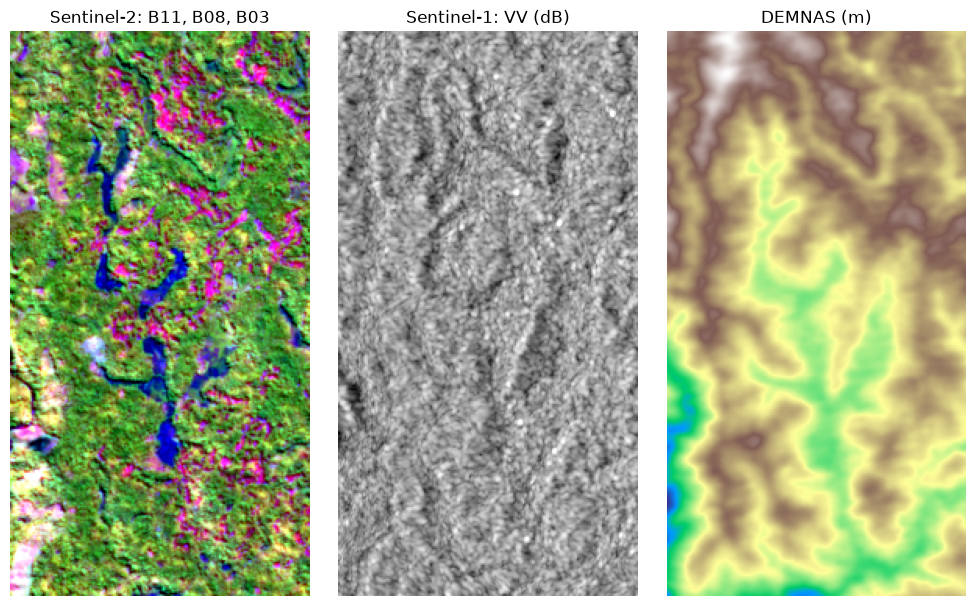

Sentinel-2, selisih terbesar dengan data Praktik 1: 0.0
Sentinel-1, selisih terbesar dengan data Praktik 1: 0.0


In [10]:
def regang(a):
    lo, hi = np.nanpercentile(a, (2, 98))
    return np.clip((a - lo) / (hi - lo), 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(10, 6))
ax[0].imshow(np.dstack([regang(s2[8]), regang(s2[6]), regang(s2[1])])); ax[0].set_title('Sentinel-2: B11, B08, B03')
ax[1].imshow(10 * np.log10(s1[0]), cmap='gray', vmin=-20, vmax=2); ax[1].set_title('Sentinel-1: VV (dB)')
ax[2].imshow(dem, cmap='terrain'); ax[2].set_title('DEMNAS (m)')
for a in ax: a.set_axis_off()
plt.tight_layout(); plt.savefig('hasil/tiga_data_unduhan.png', dpi=130); plt.show()

with rasterio.open('../praktik-1/sentinel2_l2a_20250721_10m.tif') as acuan:
    print('Sentinel-2, selisih terbesar dengan data Praktik 1:', float(np.nanmax(np.abs(acuan.read() - s2))))
with rasterio.open('../praktik-1/sentinel1_rtc_20240830_10m.tif') as acuan:
    print('Sentinel-1, selisih terbesar dengan data Praktik 1:', float(np.nanmax(np.abs(acuan.read() - s1))))

## 7. Produk utuh melalui Copernicus Data Space

Untuk produk utuh, misalnya `.SAFE` Sentinel-1 GRD yang akan diolah sendiri dengan SNAP, gunakan katalog Copernicus Data Space Ecosystem (CDSE). Pencariannya terbuka.

In [11]:
saring = (f"Collection/Name eq 'SENTINEL-2' and contains(Name,'MSIL2A') "
          f"and OData.CSC.Intersects(area=geography'SRID=4326;POINT({TITIK[0]} {TITIK[1]})') "
          "and ContentDate/Start gt 2025-07-20T00:00:00.000Z and ContentDate/Start lt 2025-07-22T00:00:00.000Z")
r = requests.get('https://catalogue.dataspace.copernicus.eu/odata/v1/Products', params={'$filter': saring, '$top': 10}, timeout=120)
r.raise_for_status()
pd.DataFrame([{'Nama': p['Name'], 'Ukuran_MB': round(p['ContentLength'] / 1e6), 'Id': p['Id']} for p in r.json()['value']])

,Nama,Ukuran_MB,Id
0,S2A_MSIL2A_20250721T025201_N0511_R132_T49MCM_2...,1058,8a864d51-48c0-4749-98c1-3d60a45b1225
1,S2B_MSIL2A_20250721T023529_N0511_R089_T49MCM_2...,201,84234b1b-ce2f-4e92-99de-ebc6cd7956bb


Mengunduhnya memerlukan akun CDSE dan token. Sel berikut sengaja tidak dijalankan otomatis, karena ukurannya besar. **Jangan menulis kata sandi di notebook**; isi lewat `getpass` saat diminta.

```python
from getpass import getpass
token = requests.post('https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token',
                      data={'client_id': 'cdse-public', 'grant_type': 'password', 'username': input('Email: '), 'password': getpass('Kata sandi: ')}).json()['access_token']
url = f"https://download.dataspace.copernicus.eu/odata/v1/Products({produk_id})/$value"
with requests.get(url, headers={'Authorization': f'Bearer {token}'}, stream=True) as r, open('produk.zip', 'wb') as f:
    for potong in r.iter_content(1 << 20):
        f.write(potong)
```